In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

client_train_data = pd.read_csv("data/train/client_train.csv", low_memory=False)
invoice_train_data = pd.read_csv("data/train/invoice_train.csv",  low_memory=False)

# fraud label in percent, indexed by client_id, so features can be joined onto it
client_fraud_pct = client_train_data.set_index("client_id").target.rename("fraud %") * 100

def plot_fraud_rate(ax, plot_data, x, title):
    """Fraud rate (mean of "fraud %") per group in column x; whiskers are 95% bootstrap CIs."""
    sns.barplot(data=plot_data, x=x, y="fraud %", errorbar=("ci", 95), color="#2a6fdb", width=0.55, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", label_type="center",
                 bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.85))
    ax.axhline(client_fraud_pct.mean(), color="gray", ls="--")
    ax.set(title=f"{title}\n(dashed line: all clients {client_fraud_pct.mean():.1f}%)", ylabel="fraud rate (%)")
    sns.despine(ax=ax, left=True)

In [2]:
# Clean the per-invoice columns (the baseline in section 3 uses them too)
invoices = invoice_train_data.copy()
invoices["invoice_date"] = pd.to_datetime(invoices["invoice_date"])
invoices["counter_type"] = invoices["counter_type"].map({"ELEC": 0, "GAZ": 1})
# counter_statue is a numeric code, except for 13 invoices holding the letter "A": those become missing
invoices["counter_statue"] = pd.to_numeric(invoices["counter_statue"], errors="coerce")

## 1. The data

In [3]:
# Two tables: one row per client (with the fraud label), one row per invoice
print("Clients:", client_train_data.shape, "| Invoices:", invoice_train_data.shape)
print("Clients that have invoices:", invoice_train_data["client_id"].nunique(), "of", len(client_train_data))
print("Invoices per client (min / median / max):",
      invoice_train_data.groupby("client_id").size().agg(["min", "median", "max"]).tolist())
display(client_train_data.head(3))
display(invoice_train_data.head(3))

Clients: (135493, 6) | Invoices: (4476749, 16)
Clients that have invoices: 135493 of 135493
Invoices per client (min / median / max): [1.0, 30.0, 439.0]


,disrict,client_id,client_catg,region,creation_date,target
0,60,train_Client_0,11,101,31/12/1994,0.0
1,69,train_Client_1,11,107,29/05/2002,0.0
2,62,train_Client_10,11,301,13/03/1986,0.0


,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,train_Client_0,2014-03-24,11,1335667,0,203,8,1,82,0,0,0,14302,14384,4,ELEC
1,train_Client_0,2013-03-29,11,1335667,0,203,6,1,1200,184,0,0,12294,13678,4,ELEC
2,train_Client_0,2015-03-23,11,1335667,0,203,8,1,123,0,0,0,14624,14747,4,ELEC


**Columns we leave out of the model.** Some columns say the same thing as another one, so keeping both adds noise without adding information:
- `tarif_type`: 99.6% correlated with `counter_type`. We keep `counter_type`; the number of tariff types per client is still built later as a feature.
- `new_index`: 99.3% correlated with `old_index`. The difference between the two is built later as a feature.
- `disrict`: a coarser version of `region`, which we keep.

We tried dropping `counter_code` and `counter_statue` too, but the model flagged about 800 more honest clients, so they stay, along with the four consumption levels.

In [4]:
DROP_COLS = ["tarif_type", "new_index", "disrict"]  # applied when the feature table is built below

## 2. Fraud is rare, so accuracy is the wrong yardstick

<Axes: xlabel='target', ylabel='count'>

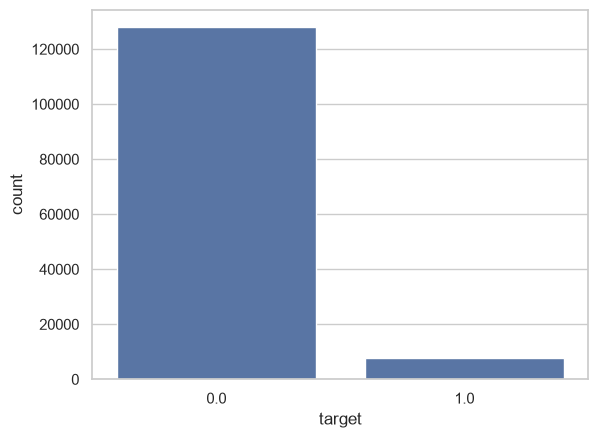

In [5]:
import seaborn as sns
sns.countplot(data=client_train_data, x="target")
# We see a very imbalanced result

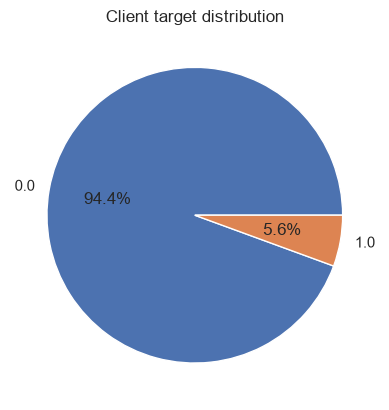

In [6]:
import matplotlib.pyplot as plt

target_counts = client_train_data["target"].value_counts().sort_index()
plt.pie(
    target_counts,
    labels=target_counts.index,
    autopct="%1.1f%%"
)
plt.title("Client target distribution")
plt.show()

In [7]:
# A model that never flags anyone already looks very accurate - that is why we do not judge by accuracy
no_fraud_accuracy = 1 - client_train_data["target"].mean()
print(f"Accuracy of always predicting 'no fraud': {no_fraud_accuracy:.1%}")

Accuracy of always predicting 'no fraud': 94.4%


**AUC (area under the ROC curve), in plain words:** pick one fraud client and one honest client at random.
AUC is the chance that the model gives the fraud client the higher risk score.
0.5 = coin flip, 1.0 = perfect ranking. It rewards ranking risky clients first, which is what an inspection list needs.

In [8]:
# One row per client: start from the client table, add invoice summaries below
client_data = client_train_data.set_index("client_id")
y = client_data["target"]
X = client_data[[c for c in ["client_catg", "disrict", "region", "creation_date"] if c not in DROP_COLS]].copy()

In [9]:
from sklearn.model_selection import train_test_split

# One row per client, so a plain split keeps each client on one side only.
# 25% test set; stratify keeps the fraud ratio the same in both parts.
# Done once, up front, so every model below is scored on the same clients.
train_ids, test_ids = train_test_split(y.index, test_size=0.25, stratify=y, random_state=42)
y_train, y_test = y.loc[train_ids], y.loc[test_ids]

In [10]:
X['client_catg'] = X['client_catg'].astype(int)

X["creation_date"] = pd.to_datetime(X["creation_date"]).astype("int64")

C:\Users\Elliot\AppData\Local\Temp\ipykernel_39304\3518614645.py:3: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  X["creation_date"] = pd.to_datetime(X["creation_date"]).astype("int64")


## 3. Baseline: LightGBM on the raw data, no feature engineering

In [11]:
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

# Raw data only: the client columns plus the average of every raw invoice column per client.
# (The model needs one row per client, so averaging is the one unavoidable roll-up - no new ideas added.)
raw_invoice_cols = [c for c in ["tarif_type", "counter_statue", "counter_code", "reading_remarque", "counter_coefficient",
                                "consommation_level_1", "consommation_level_2", "consommation_level_3", "consommation_level_4",
                                "old_index", "new_index", "months_number", "counter_type"] if c not in DROP_COLS]
X_base = X.join(invoices.groupby("client_id")[raw_invoice_cols].mean())

results = []  # one row per model: train and test AUC, for the results table at the end
def record(name, model, X_all):
    results.append({
        "model": name,
        "train_auc": roc_auc_score(y_train, model.predict_proba(X_all.loc[train_ids])[:, 1]),
        "test_auc": roc_auc_score(y_test, model.predict_proba(X_all.loc[test_ids])[:, 1]),
    })

baseline = LGBMClassifier(random_state=42, verbose=-1).fit(X_base.loc[train_ids], y_train)
record("1. Baseline (raw data, default settings)", baseline, X_base)
print(results[-1])

{'model': '1. Baseline (raw data, default settings)', 'train_auc': 0.8715689687023832, 'test_auc': 0.7962221796139821}


## 4. Feature engineering

In [ ]:
# One row per client is what we predict on, so invoices get summarised per client further down.
# First, a few per-invoice columns that those summaries are built from.
invoices["diff_index"] = invoices["new_index"] - invoices["old_index"]
# All four consumption levels added up per invoice
invoices["total_cons"] = invoices[["consommation_level_1", "consommation_level_2",
                                   "consommation_level_3", "consommation_level_4"]].sum(axis=1)
by_client = invoices.groupby("client_id")

# new_index - old_index: meter readings that go backwards or do not move
index_diff = invoice_train_data.new_index - invoice_train_data.old_index
index_diff_by_client = index_diff.groupby(invoice_train_data.client_id)

plot_data = pd.DataFrame(
    {
        "reading ever went backwards": index_diff_by_client.min().lt(0).map({False: "never", True: "at least once"})
        .astype(pd.CategoricalDtype(["never", "at least once"])),
        "share of invoices without meter movement": pd.cut(
            (index_diff == 0).groupby(invoice_train_data.client_id).mean(),
            [-0.001, 0, 0.1, 0.5, 1],
            labels=["0%", "0-10%", "10-50%", "50-100%"],
        ),
    }
).join(client_fraud_pct)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
plot_fraud_rate(axes[0], plot_data, "reading ever went backwards", "new_index < old_index")
plot_fraud_rate(axes[1], plot_data, "share of invoices without meter movement", "new_index == old_index")
fig.tight_layout()

In [ ]:
# reading_remarque is a code the meter reader assigns at each reading. We use it as it comes (not engineered),
# but fraud rates differ a lot by value. Share of clients with at least one invoice carrying that code who are fraud:
pairs = invoices[["client_id", "reading_remarque"]].drop_duplicates().join(y, on="client_id")
remarque_table = pairs.groupby("reading_remarque")["target"].agg(n_clients="size", fraud_rate_pct=lambda s: round(s.mean() * 100, 2))
print(f"Overall fraud rate: {y.mean() * 100:.2f}%")
display(remarque_table.sort_values("fraud_rate_pct", ascending=False))

# Small helper used below: fraud rate per group of clients
def fraud_rate_by(groups, name):
    table = y.groupby(groups, observed=True).agg(n_clients="size", fraud_rate_pct=lambda s: round(s.mean() * 100, 2))
    table.index.name = name
    return table

# reading_remarque: share of each client's invoices per code
remarque_share = pd.crosstab(invoice_train_data.client_id, invoice_train_data.reading_remarque, normalize="index")
plot_data = remarque_share.join(client_fraud_pct)

# left: clients who ever received the code (a client can appear under several codes)
code_received = pd.concat(
    {c: plot_data[plot_data[c] > 0] for c in (6, 7, 8, 9)}, names=["code"]
).reset_index(level="code")

# right: how large is the share of code-8 invoices?
plot_data["share of invoices coded 8"] = pd.cut(
    plot_data[8], [-0.001, 0, 0.25, 0.5, 0.75, 1], labels=["0%", "0-25%", "25-50%", "50-75%", "75-100%"]
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
plot_fraud_rate(axes[0], code_received, "code", "Clients who ever got the code")
plot_fraud_rate(axes[1], plot_data, "share of invoices coded 8", "Share of a client's invoices with code 8")
fig.tight_layout()

In [ ]:
X = X_base.copy()  # engineered features are added on top of the raw baseline columns

In [ ]:
# If the result is negative, this might indicate a fraud. This is *drumroll* FEATURE ENGINEERING!
# Per client we keep the average difference between new and old meter index
X["mean_diff_index"] = by_client["diff_index"].mean()

In [ ]:
# How many different tariff types and meters does each client have across their invoices?
# (a client switching between tariffs could be a fraud signal), plus how many invoices they have.
# (Average months and share of gas are already in the raw baseline columns.)
X["n_tarif_types"] = by_client["tarif_type"].nunique()
X["n_counters"] = by_client["counter_number"].nunique()
X["n_invoices"] = by_client.size()

# tarif_type changes, counted in date order per (client, counter_type):
# ELEC and GAZ use different tariff codes, so mixing them would fake switches
tarif_by_date = invoice_train_data.assign(
    date=pd.to_datetime(invoice_train_data.invoice_date)
).sort_values("date", kind="stable")
tarif_changed = tarif_by_date.groupby(["client_id", "counter_type"]).tarif_type.diff().fillna(0).ne(0)

plot_data = pd.DataFrame(
    {
        "tariff switches (4 = 4 or more)": tarif_changed.groupby(tarif_by_date.client_id).sum().clip(upper=4),
        "distinct tariffs on one meter type (3 = 3 or more)": invoice_train_data.groupby(["client_id", "counter_type"])
        .tarif_type.nunique()
        .groupby("client_id")
        .max()
        .clip(upper=3),
    }
).join(client_fraud_pct)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
plot_fraud_rate(axes[0], plot_data, "tariff switches (4 = 4 or more)", "Tariff changes between consecutive invoices")
plot_fraud_rate(axes[1], plot_data, "distinct tariffs on one meter type (3 = 3 or more)", "Distinct tariffs on the same meter type")
fig.tight_layout()

In [ ]:
display(fraud_rate_by(X["n_tarif_types"], "number of tariff types"))

In [ ]:
# Feature 1: consumption pattern per client (all four consumption levels added up per invoice).
# Fraudsters often under-report, so low, flat or zero consumption can stand out.
# (The average per consumption level is already in the raw baseline columns.)
X["cons_mean"] = by_client["total_cons"].mean()
X["cons_std"] = by_client["total_cons"].std().fillna(0)  # clients with one invoice have no spread
X["cons_min"] = by_client["total_cons"].min()
X["cons_zero_share"] = (invoices["total_cons"] == 0).groupby(invoices["client_id"]).mean()

In [ ]:
display(fraud_rate_by(X["cons_zero_share"].gt(0).map({False: "never zero", True: "has zero-consumption invoices"}), "zero consumption"))

In [ ]:
# Feature 2: negative index differences per client (the meter reading went backwards).
# Count and share, because 1 negative out of 1 invoice (100%) is not the same as 1 out of 50 (2%).
negative = invoices["diff_index"] < 0
X["n_negative_diff"] = negative.groupby(invoices["client_id"]).sum()
X["share_negative_diff"] = negative.groupby(invoices["client_id"]).mean()

In [ ]:
display(fraud_rate_by(pd.cut(X["n_negative_diff"], [-1, 0, 1, 5, float("inf")], labels=["0", "1", "2-5", "6+"]),
                      "invoices with index going backwards"))

In [ ]:
# Feature 3: consumption drop per client = (average of the later half of invoices - average of the earlier half)
# relative to the earlier half. A sudden drop is the classic "tampered meter" shape.
order = invoices.sort_values(["client_id", "invoice_date"])
position = order.groupby("client_id").cumcount()
n_invoices = order.groupby("client_id")["client_id"].transform("size")
is_late = position >= n_invoices / 2
early_mean = order[~is_late].groupby("client_id")["total_cons"].mean()
late_mean = order[is_late].groupby("client_id")["total_cons"].mean()
X["cons_change"] = ((late_mean - early_mean) / (early_mean + 1)).reindex(X.index).fillna(0)  # +1 avoids dividing by zero

In [ ]:
display(fraud_rate_by(pd.cut(X["cons_change"], [-float("inf"), -0.5, -0.1, 0.1, float("inf")],
                             labels=["drop over 50%", "drop 10-50%", "stable (+/-10%)", "increase over 10%"]),
                      "consumption change, later vs earlier invoices"))

In [ ]:
cm = X.select_dtypes(include=["number"]).corr(method="pearson")
sns.heatmap(cm)

## 5. Tuning vs. feature engineering

In [ ]:
# Same client split as for the baseline, now with the engineered features
X_train, X_test = X.loc[train_ids], X.loc[test_ids]

Each tuned model is searched twice, so the results table can show both:
- **Fast mode:** quick sanity check, 20% of training clients and 4 random setting combos. Train AUC only.
- **Full mode:** all training data and all 36 combos. This is the one scored on the test set.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

# The scaler lives inside the pipeline, so the same scaling is applied to train AND test data
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lgbm", LGBMClassifier(random_state=42, verbose=-1)),
])
pg = {
    "lgbm__learning_rate": [0.01, 0.1, 0.2, 1],
    "lgbm__n_estimators": [10, 100, 200],
    "lgbm__subsample_for_bin": [1000, 10000, 20000],
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def tune(X_tr, fast):
    """Same settings search for any feature set, so the comparison is fair."""
    X_fit = X_tr.sample(frac=0.2, random_state=42) if fast else X_tr
    if fast:
        search = RandomizedSearchCV(pipe, pg, n_iter=4, cv=cv, n_jobs=8, scoring="roc_auc", random_state=42)
    else:
        search = GridSearchCV(pipe, pg, cv=cv, n_jobs=8, scoring="roc_auc")
    return search.fit(X_fit, y_train.loc[X_fit.index])

def record_tuned(name, search_fast, search_full, X_all):
    """One row per tuned model: train AUC in both modes, test AUC from the full run only."""
    results.append({
        "model": name,
        "train_auc": roc_auc_score(y_train, search_full.predict_proba(X_all.loc[train_ids])[:, 1]),
        "train_auc_fast": roc_auc_score(y_train, search_fast.predict_proba(X_all.loc[train_ids])[:, 1]),
        "test_auc": roc_auc_score(y_test, search_full.predict_proba(X_all.loc[test_ids])[:, 1]),
    })

# Attempt 1: tune the settings on the raw baseline columns
search_base_fast = tune(X_base.loc[train_ids], fast=True)
search_base = tune(X_base.loc[train_ids], fast=False)
record_tuned("2. Baseline + tuned settings", search_base_fast, search_base, X_base)
print("Best settings (full):", search_base.best_params_, "| cross-validated AUC:", round(search_base.best_score_, 4))

Tuning barely moves the score, so we went into feature engineering instead.

In [ ]:
# Attempt 2: engineered features
model_fe = LGBMClassifier(random_state=42, verbose=-1).fit(X_train, y_train)
record("3. Engineered features, default settings", model_fe, X)

gscv_fast = tune(X_train, fast=True)
gscv = tune(X_train, fast=False)  # full mode: the model scored on the test set below
record_tuned("4. Engineered features + tuned settings", gscv_fast, gscv, X)
print("Best settings (full):", gscv.best_params_, "| cross-validated AUC:", round(gscv.best_score_, 4))

## 6. Results

In [ ]:
# train_auc = full mode for tuned models (models 1 and 3 are untuned, so they only have this one train column)
# train_auc_fast = fast-mode search, tuned models only. test_auc = full mode only, never the fast search.
results_table = pd.DataFrame(results).set_index("model")[["train_auc", "train_auc_fast", "test_auc"]].round(4)
display(results_table)
# A big gap between train and test AUC would mean overfitting; both low would mean underfitting
results_table.plot.bar(rot=15, figsize=(9, 4), ylim=(0.5, 1), title="AUC by model: train (full and fast) vs test (full)")
plt.show()

In [ ]:
y_pred = gscv.predict(X_test)
print("Test AUC:", round(roc_auc_score(y_test, gscv.predict_proba(X_test)[:, 1]), 4))

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["predicted honest", "predicted fraud"], yticklabels=["actually honest", "actually fraud"])
tn, fp, fn, tp = cm.ravel()
print(f"Fraud caught: {tp} of {tp + fn} | honest clients wrongly flagged: {fp} of {fp + tn}")

In [ ]:
from sklearn.metrics import precision_score, recall_score

# Recall: of all clients who really are fraud, how many did the model catch?
# Precision: of all clients the model flagged, how many really are fraud?
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
print(f"Recall: {recall:.1%} ({tp} of {tp + fn} fraud clients caught)")
print(f"Precision: {precision:.1%} ({tp} of {tp + fp} flagged clients really are fraud)")

## 7. Catching more fraud: weighting and threshold
The model above only flags a client when it is more than 50% sure, which is rare when fraud is this uncommon, so recall is low. Two fixes, each changing one thing:
1. **Fraud weighting:** during training, missing a fraud client costs more than wrongly flagging an honest one.
2. **Lower flagging threshold:** flag a client at a lower fraud probability. The cutoff is chosen on the training data (predictions made on clients the model did not train on), never on the test set.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

# Same tuned settings as model 4, only with fraud weighting added
best_settings = {k.replace("lgbm__", ""): v for k, v in gscv.best_params_.items()}
model_weighted = LGBMClassifier(random_state=42, verbose=-1, class_weight="balanced", **best_settings)

# Business knob: the share of fraud clients we want to catch. Higher = fewer missed frauds, more false alarms.
RECALL_TARGET = 0.70

# Fraud probabilities for training clients, each predicted by a model that never saw that client
oof_proba = cross_val_predict(clone(model_weighted), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
precision_c, recall_c, thresholds = precision_recall_curve(y_train, oof_proba)
# Highest threshold that still reaches the recall target (= fewest false alarms for that recall)
threshold = thresholds[recall_c[:-1] >= RECALL_TARGET].max()
print(f"Chosen threshold: {threshold:.3f} (default is 0.5)")

In [ ]:
model_weighted.fit(X_train, y_train)
proba_default = gscv.predict_proba(X_test)[:, 1]
proba_weighted = model_weighted.predict_proba(X_test)[:, 1]

def flag_summary(name, proba, cutoff):
    flagged = proba >= cutoff
    tp = int((flagged & (y_test == 1)).sum())
    return {
        "setup": name, "threshold": round(cutoff, 3),
        "recall": round(tp / int((y_test == 1).sum()), 3),
        "precision": round(tp / max(int(flagged.sum()), 1), 3),
        "fraud caught": tp, "honest wrongly flagged": int(flagged.sum()) - tp,
    }

display(pd.DataFrame([
    flag_summary("Model 4 (no weighting, threshold 0.5)", proba_default, 0.5),
    flag_summary("+ fraud weighting, threshold 0.5", proba_weighted, 0.5),
    flag_summary("+ fraud weighting + chosen threshold", proba_weighted, threshold),
]).set_index("setup"))